## 멀티모달 RAG
---

### 가상환경과 패키지 설치

In [1]:
import shutil
import sys

print("Python:", sys.version.split()[0])
print("가상환경 경로:", sys.prefix)
print("가상환경 안에서 실행 중?", ".venv" in sys.prefix)
print()

# OS 패키지 확인 (pip로 설치되지 않는 것들)
print("Poppler  :", "OK" if shutil.which("pdftoppm") else "✗ 미설치 — Path 확인 후 재시작")
print("Tesseract:", "OK" if shutil.which("tesseract") else "✗ 미설치 — Path 확인 후 재시작")
print()

# 파이썬 패키지 확인
for mod in ["langchain", "unstructured", "chromadb", "tiktoken", "PIL"]:
    try:
        __import__(mod)
        print(f"{mod:14s}: OK")
    except ImportError:
        print(f"{mod:14s}: ✗ 미설치")

Python: 3.11.9
가상환경 경로: c:\workspace\multimodal-rag\.venv
가상환경 안에서 실행 중? True

Poppler  : OK
Tesseract: OK

langchain     : OK
unstructured  : OK
chromadb      : OK
tiktoken      : OK
PIL           : OK


### 추출함수 만들기
---

In [2]:
# PDF에서 표, 텍스트, 이미지 같은 요소를 추출하기 위해 사용되는 기능
import os
from pathlib import Path

from langchain_text_splitters import CharacterTextSplitter
from unstructured.partition.pdf import partition_pdf

def extract_pdf_elements(path, fname): # PDF에서 elements를 추출하는 함수
    """
    PDF 파일에서 이미지, 테이블, 텍스트 블록을 추출합니다.
    path: 파일 경로 (추출된 이미지 파일이 저장될 위치)
    fname: 파일 이름
    """
    return partition_pdf( # unstructured가 주는 함수
        filename=path + fname,
        strategy="hi_res",              # 레이아웃 분석 모델로 정밀 추출
        extract_images_in_pdf=True,     # PDF에서 이미지를 추출
        infer_table_structure=True,     # 테이블 구조를 추론
        chunking_strategy="by_title",   # 타이틀을 기준으로 텍스트를 블록으로 분할
        max_characters=4000,            # 최대 4000자로 텍스트 블록을 제한
        new_after_n_chars=3000,         # 3000자 이후에 새로운 블록 생성
        combine_text_under_n_chars=2000, # 2000자 이하의 텍스트는 결합
        extract_image_block_output_dir=path+"/figures",     # 이미지가 저장될 경로 설정
        languages=["kor", "eng"]
    )

print("extract_pdf_elements 정의 완료")

extract_pdf_elements 정의 완료


In [3]:
def categorize_elements(raw_pdf_elements): # elements를 분류
    """
    PDF에서 추출한 요소들을 테이블과 텍스트로 분류합니다.
    raw_pdf_elements: unstructured.documents.elements 리스트
    """
    tables = []
    texts = []
    for element in raw_pdf_elements:
        if "unstructured.documents.elements.Table" in str(type(element)):
            tables.append(str(element))     # 테이블 요소를 저장
        elif "unstructured.documents.elements.CompositeElement" in str(type(element)):
            texts.append(str(element))      # 텍스트 요소를 저장
    return texts, tables

print("categorize_elements 정의 완료")

categorize_elements 정의 완료


In [4]:

# 현재 작업 디렉터리 경로를 반환합니다.
current_directory = os.getcwd()

# fname: 처리할 PDF 파일 이름 / fpath: PDF가 저장된 폴더 경로
fname = "assignment.pdf"
fpath = os.path.join(os.path.dirname(current_directory), "data/" )

# 실행하면 2~3분 걸린다. 멈춘게 아니니 기다리세요.
print("현재 스크립트의 위치:", current_directory)
print("pdf 위치:", fpath)

현재 스크립트의 위치: c:\workspace\multimodal-rag\notebooks
pdf 위치: c:\workspace\multimodal-rag\data/


### 추출 실행
---

In [5]:
import time

start = time.time()

raw_pdf_elements = extract_pdf_elements(fpath, fname)

print(f"추출 완료 - {time.time() - start:.1f} 초 소요")
print("추출 된 요소 수", len(raw_pdf_elements))

Thank you for using Unstructured Open Source! Try Unstructured's commercial offering for improved output quality. 10,000 free pages to start. Learn more: https://transform.unstructured.io/?utm_source=unstructured_oss Hide this notice: UNSTRUCTURED_DISABLE_NOTICE=1
Loading weights: 100%|██████████| 367/367 [00:00<00:00, 3939.88it/s]


추출 완료 - 71.5 초 소요
추출 된 요소 수 19


In [6]:
texts, tables = categorize_elements(raw_pdf_elements)

print("텍스트 블록 수:", len(texts))
print("표 블록 수:", len(tables))

텍스트 블록 수: 10
표 블록 수: 9


### 어떤 요소들이 나왔는지 집계
---

In [7]:
from collections import Counter

type_counts = Counter(str(type(el)).split(".")[-1].strip("'>") for el in raw_pdf_elements)

for element_type, count in type_counts.most_common():
    print(f"{element_type:22s}: {count}개")

CompositeElement      : 10개
Table                 : 9개


### 추출된 이미지 확인
---

In [8]:
project_dir = Path(fpath) / "figures"

if project_dir.exists():
    image_files = sorted(
        p for p in project_dir.iterdir()
        if p.suffix.lower() in (".jpg", ".jpeg", ".png")
    )
    print(f"추출된 이미지: {len(image_files)}개\n")
    for p in image_files[:10]:
        print(f"    {p.name}  ({p.stat().st_size // 1024} KB)")
else:
    print("figures 폴더가 없습니다")

추출된 이미지: 19개

    figure-1-1.jpg  (269 KB)
    figure-10-17.jpg  (51 KB)
    figure-14-18.jpg  (45 KB)
    figure-14-19.jpg  (43 KB)
    figure-3-2.jpg  (4 KB)
    figure-4-3.jpg  (10 KB)
    figure-4-4.jpg  (8 KB)
    figure-6-10.jpg  (39 KB)
    figure-6-5.jpg  (18 KB)
    figure-6-6.jpg  (19 KB)


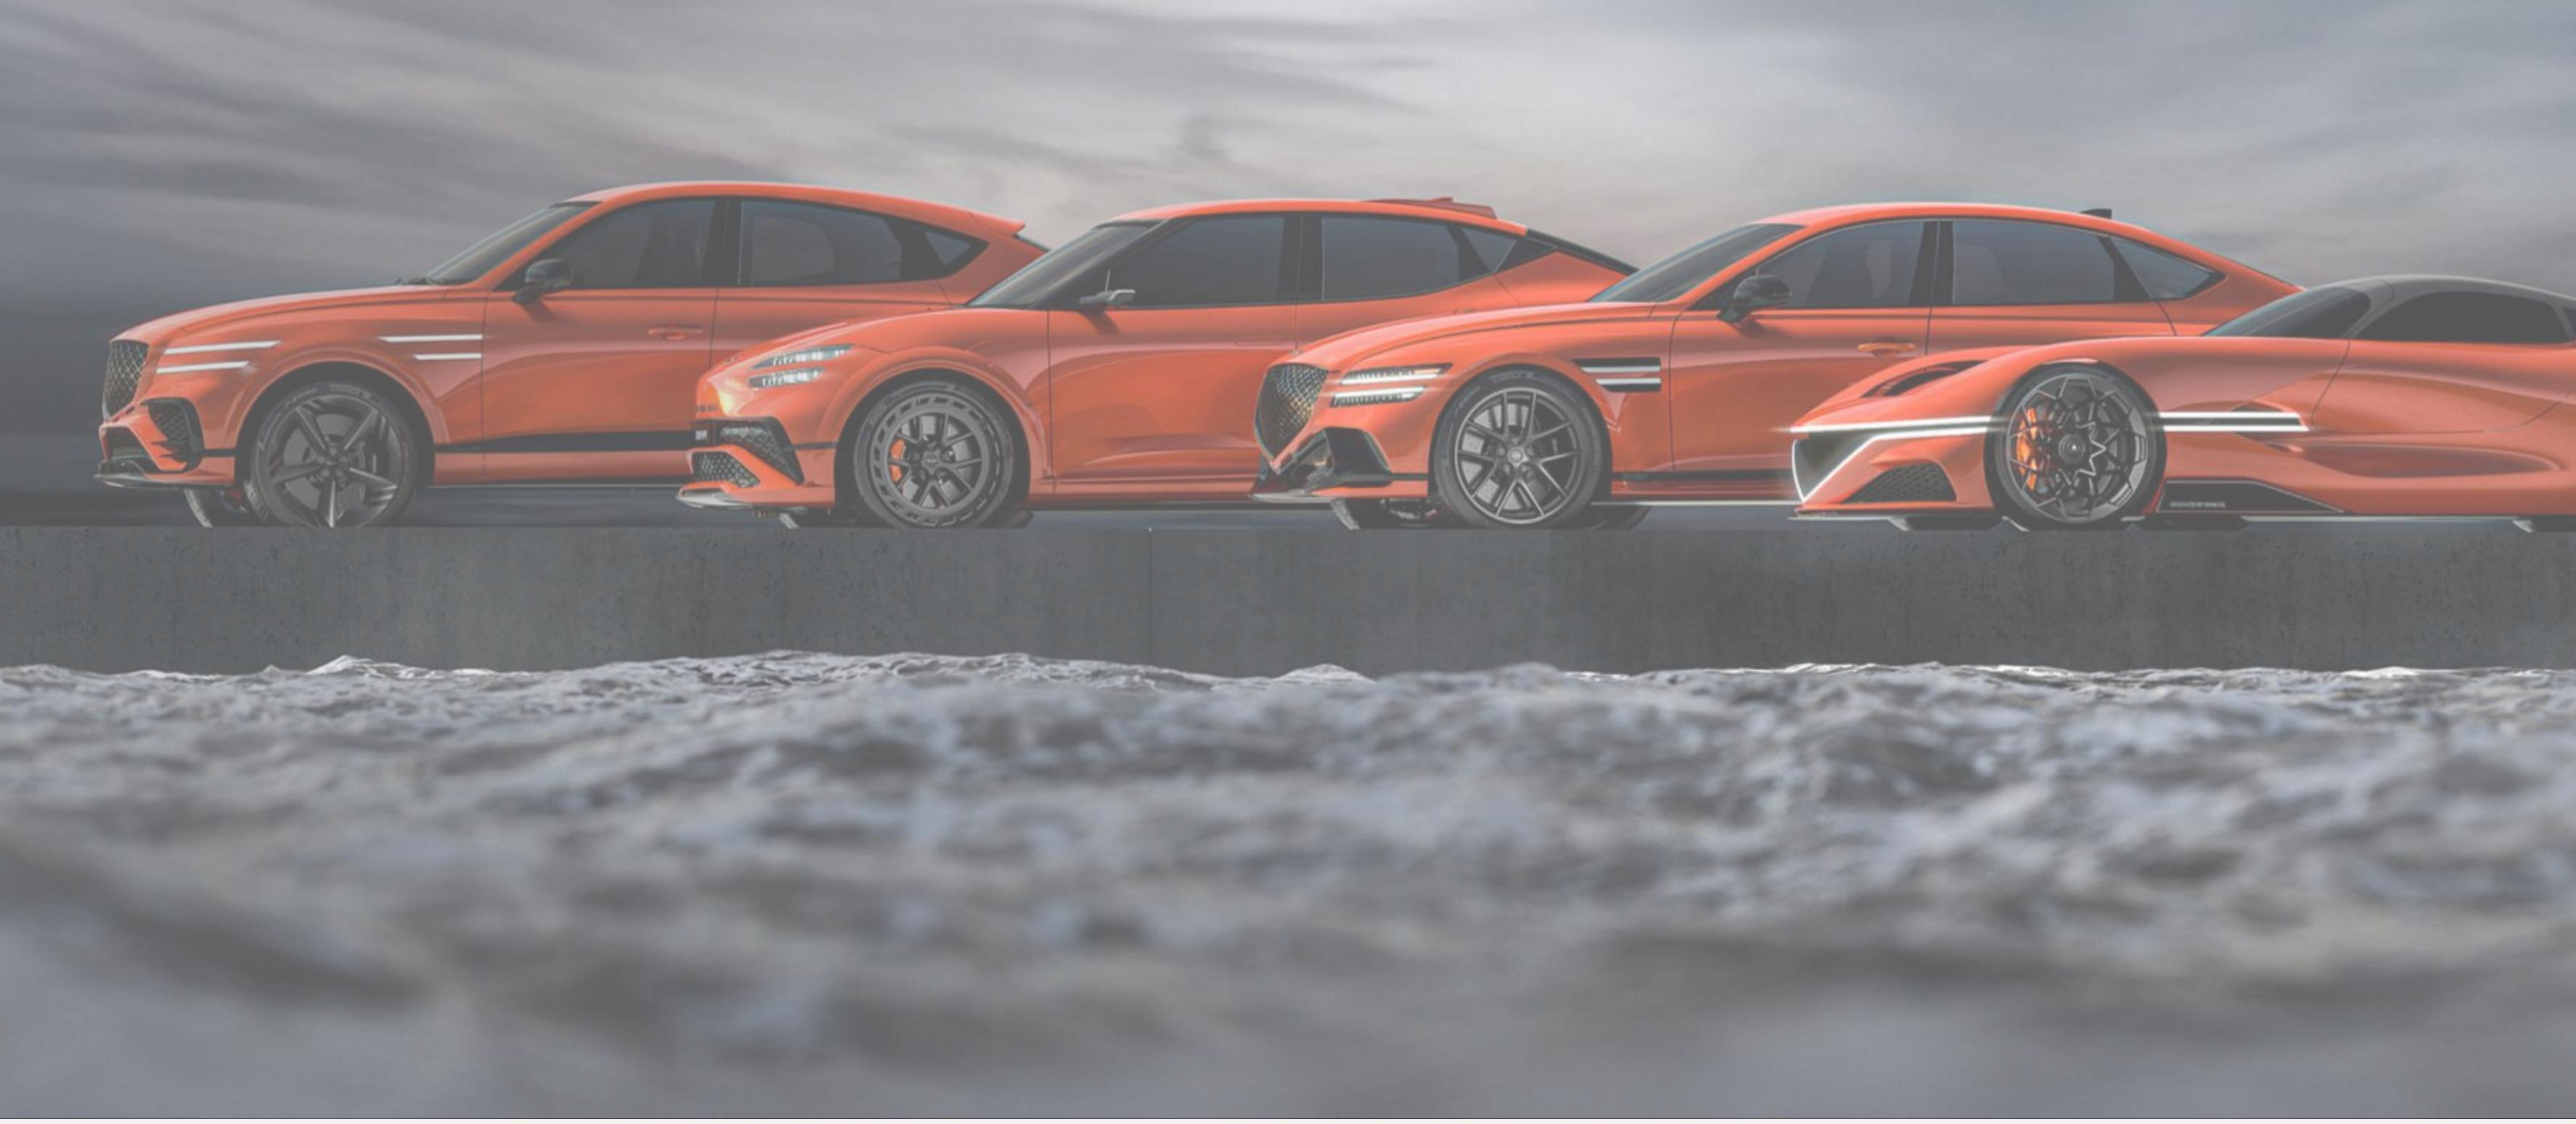

In [9]:
from IPython.display import Image, display

if project_dir.exists() and image_files:
    display(Image(filename=str(image_files[0]), width=500))
else:
    print("표시할 이미지가 없습니다.")

In [10]:
text_splitter = CharacterTextSplitter.from_tiktoken_encoder(
    chunk_size = 400,
    chunk_overlap = 80,
)

joined_texts = " ".join(texts)
texts_2k_token = text_splitter.split_text(joined_texts)

print("원본 블록 수 :", len(texts))
print("분할 후 블록 수:", len(texts_2k_token))
print("전체 글자 수:", len(joined_texts))

원본 블록 수 : 10
분할 후 블록 수: 12
전체 글자 수: 3378


In [11]:
print("=" * 60)
print("[원본 texts[0]] 앞 300자")
print("=" * 60)
print(texts[0][:300])
print()

print("=" * 60)
print("[분할 texts_2k_token[0]] 앞 300자")
print("=" * 60)
print(texts_2k_token[0][:300])

[원본 texts[0]] 앞 300자
@@ uyunnat

현 대 자동차 2025 년 3 분 기 경 영 실적 발표 2025 년 10 월 30

일

유 의 사항

본 자 료 는 2025 년 3 분 기 실 적 에 대한 외 부 감 사 인 의 회 계 감 사 가 완 료 되지 않은 상 태 에서 투자자 여 러 분 들 의 편 의 를 위하여 작성된 자 료 로서, 제시된 자 료 의 내용 중 일 회 계 감사 과 정 에서 ASS 수 있 음 을 양 지 하시기 바랍니다. 넌 느 2 TN

[분할 texts_2k_token[0]] 앞 300자
@@ uyunnat

현 대 자동차 2025 년 3 분 기 경 영 실적 발표 2025 년 10 월 30

일

유 의 사항

본 자 료 는 2025 년 3 분 기 실 적 에 대한 외 부 감 사 인 의 회 계 감 사 가 완 료 되지 않은 상 태 에서 투자자 여 러 분 들 의 편 의 를 위하여 작성된 자 료 로서, 제시된 자 료 의 내용 중 일 회 계 감사 과 정 에서 ASS 수 있 음 을 양 지 하시기 바랍니다. 넌 느 2 TN 3 분 기 주요 메시지

사 / 조원


## 요약 생성
---
### API 키 불러오기

In [12]:
import os
from pathlib import Path
from dotenv import load_dotenv

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name in "notebooks" else Path.cwd()

load_dotenv(PROJECT_ROOT / ".env")

openai_api_key = os.getenv("OPENAI_API_KEY")

if not openai_api_key:
    raise ValueError("환경변수 OPENAI_API_KEY가 없습니다. .env 파일을 확인하세요.")

print(f"API Key: {openai_api_key[:7]}...{openai_api_key[-4:]}")

API Key: sk-proj...Vq0A


In [13]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI
from langchain_ollama.llms import OllamaLLM

def generate_text_summaries(texts, tables, summarize_texts=False):
    """
    텍스트 및 표 데이터를 요약하여 검색에 활용할 수 있는 요약본을 생성합니다.
    texts: 텍스트 리스트
    tables: 표 리스트
    summarize_texts: 텍스트 요약을 활성화할지 여부를 결정하는 불리언 값
    """

    # Prompt 한국어 버전
    prompt_text_kor = """당신은 표와 텍스트를 요약하여 검색에 활용할 수 있도록 돕는 도우미 입니다.
    이 요약본들은 임베딩되어 원본 텍스트나 표 요소를 검색하는데 사용될 것입니다.
    주어진 표나 텍스트의 내용을 검색에 최적화된 간결한 요약으로 작성해주세요.
    요약할 표 또는 텍스트: {element}"""

    # Prompt 영어 버전
    prompt_text_eng = """You are an assistant that summarizes tables and text so they can be used for retrieval.
    These summaries will be embedded and used to retrieve the original text or table elements.
    Write a concise summary of the given table or text, optimized for retrieval.
    Respond in Korean.
    Table or text to summarize: {element}"""


    prompt = ChatPromptTemplate.from_template(prompt_text_eng)

    model = ChatOpenAI(temperature=0, model="gpt-4o-mini")

    summarize_chain = {"element" : lambda x: x} | prompt | model | StrOutputParser()

    text_summaries = []
    table_summaries = []

    if texts and summarize_texts:
        text_summaries = summarize_chain.batch(texts, {"max_concurrency": 6})
    elif texts:
        text_summaries = texts

    if tables:
        table_summaries = summarize_chain.batch(tables, {"max_concurrency": 6})

    return text_summaries, table_summaries

text_summaries, table_summaries = generate_text_summaries(
    texts_2k_token, tables, summarize_texts=True
)
print("\n\n".join(text_summaries))
print("="*60)
print("\n\n".join(table_summaries))

현대자동차는 2025년 3분기 경영 실적을 2025년 10월 30일 발표하였으며, 해당 자료는 외부 감사가 완료되지 않은 상태에서 투자자 편의를 위해 작성되었음을 유의해야 합니다.

역대 최대 3분기 매출액 기록, 미국 시장에서 6.3%의 시장 점유율(M/S) 달성. 고수익 차종의 판매 비중 확대 지속.

고수익 차종의 판매 비중이 21%로 증가하며 2개 분기 연속 20% 이상을 기록했다. 2024년 3분기와 2025년 3분기의 글로벌 도소매 판매 현황이 포함되어 있으며, 산업 수요는 각각 +6.3%, +3.8%로 예상된다. 미국, 유럽, 국내 및 아시아태평양 지역의 판매 성장률도 제시되었다.

국내 및 아시아태평양 지역의 판매량 변화에 대한 데이터 요약: 국내 판매는 +6.3% 증가했으며, 아시아태평양 지역은 -2.1% 감소. 북미에서는 2025년 1분기 도매 및 소매 각각 315천 대 판매. 인도 내수 판매는 대리점 미포함. 중국 및 러시아 지역의 상용차 포함.

2024년 3분기와 2025년 3분기 소매 판매 데이터 요약: 

- 2024년 3분기 소매 판매량: 958천 대, 2025년 3분기: 1,006천 대 (중국 제외)
- 도매 판매량: 2024년 3분기 990천 대, 2025년 3분기 1,006천 대 (중국 제외)
- 차급별 판매 비율: SUV 72.7%, PHEV 20.4%, MEV 6.8%, MPHEV 0.2%, FCEV 0.004% (2024년 3분기 기준)
- 2025년 3분기에는 SUV 비율이 77.9%로 증가. 

판매 성장률: 전체 -0.4%, SUV +8.7%, PHEV +48.7%.

2024년 3분기와 2025년 3분기의 SUV 및 전기차(EV) 판매 비중을 나타내는 표로, 도매 판매 기준으로 지역별 전체 판매 대수 대비 비중을 보여줌. 2024년에는 HEV가 20.4%, PHEV가 6.8%, FCEV는 각각 0.004%와 0.001%로 기록됨. 판매 믹스 최적화로 시장 점유율(M/S)이 증가하며, 전년 대비 소매 판매가 90.3

## 이미지를 Base64로 포장하기
---

In [14]:
import base64
from langchain_core.messages import HumanMessage

def encode_image(image_path):
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")
image_files = sorted(
    f for f in project_dir.iterdir()
    if f.suffix.lower() in (".jpg", ".jpeg", ".png")
)

sample_b64 = encode_image(image_files[0])

print("원본파일 =>", image_files[0].name)
print("문자열 길이 :", len(sample_b64), "자")
print("앞 100자 :", sample_b64[:100])

원본파일 => figure-1-1.jpg
문자열 길이 : 367844 자
앞 100자 : /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx


In [15]:
# 이미지 요약 함수 만들기
def image_summarize(img_base64, prompt):
    """이미지 요약 생성"""
    chat = ChatOpenAI(model="gpt-4o-mini", temperature=0, max_tokens=1024)

    msg = chat.invoke(
        [
            HumanMessage(
                content=[
                    {"type": "text", "text":prompt},
                    {
                        "type": "image_url",
                        "image_url": {"url": f"data:image/jpeg;base64,{img_base64}"},
                    },
                ]
            )
        ]
    )
    return msg.content

test_prompt="""You are an assistant tasked with summarizing images for retrieval.
These summaries will be embedded and used to retrieve the raw image.
Provide a concise summary of the image that is well optimized for retrieval.
The summary should be written in Korean (Hangul)."""

print(image_summarize(sample_b64, test_prompt))

주황색 차량들이 나란히 서 있는 이미지로, 다양한 스타일의 자동차들이 포함되어 있습니다. 배경은 흐릿한 바다와 구름으로 구성되어 있습니다.


In [16]:
def generate_img_summaries(path):
    img_base64_list = []
    image_summaries = []

    prompt_kr="""당신은 기업 IR 자료의 그래프를 검색용으로 요약하는 도우미입니다.
    이 요약은 임베딩되어 원본 이미지를 검색하는 데 사용됩니다.
    다음을 반드시 포함해 한국어로 요약하세요.
    1. 그래프 종류 (막대, 도넛, 워터폴 등)
    2. 이미지에 보이는 제목, 범례 항목, 축 이름을 그대로 적을 것
    3. 범례 항목별 수치를 '항목: 기간 값 → 기간 값' 형식으로 짝지어 적을 것 (예: SUV: Q3 2024 61.7% → Q3 2025 69.5%)
    4. 범례와 수치로 볼 때 이 그래프가 무엇을 나타내는지 추론한 주제 (예: 차급별 판매 비중, 영업외손익 구성, 친환경차 판매 비중)
    그래프가 아닌 사진이나 로고라면 한 줄로만 설명하세요."""

    for img_file in sorted(os.listdir(path)):
        if img_file.endswith((".jpg", ".jpeg", ".png")):
            img_path = os.path.join(path, img_file)
            base64_image = encode_image(img_path)
            img_base64_list.append(base64_image)
            image_summaries.append(image_summarize(base64_image, prompt_kr))

    return img_base64_list, image_summaries

start = time.time()
img_base64_list, image_summaries = generate_img_summaries(str(project_dir))

print(f"이미지 요약 완료 - {time.time() - start:.1f}초 소요")

이미지 요약 완료 - 39.1초 소요


[0] figure-1-1.jpg


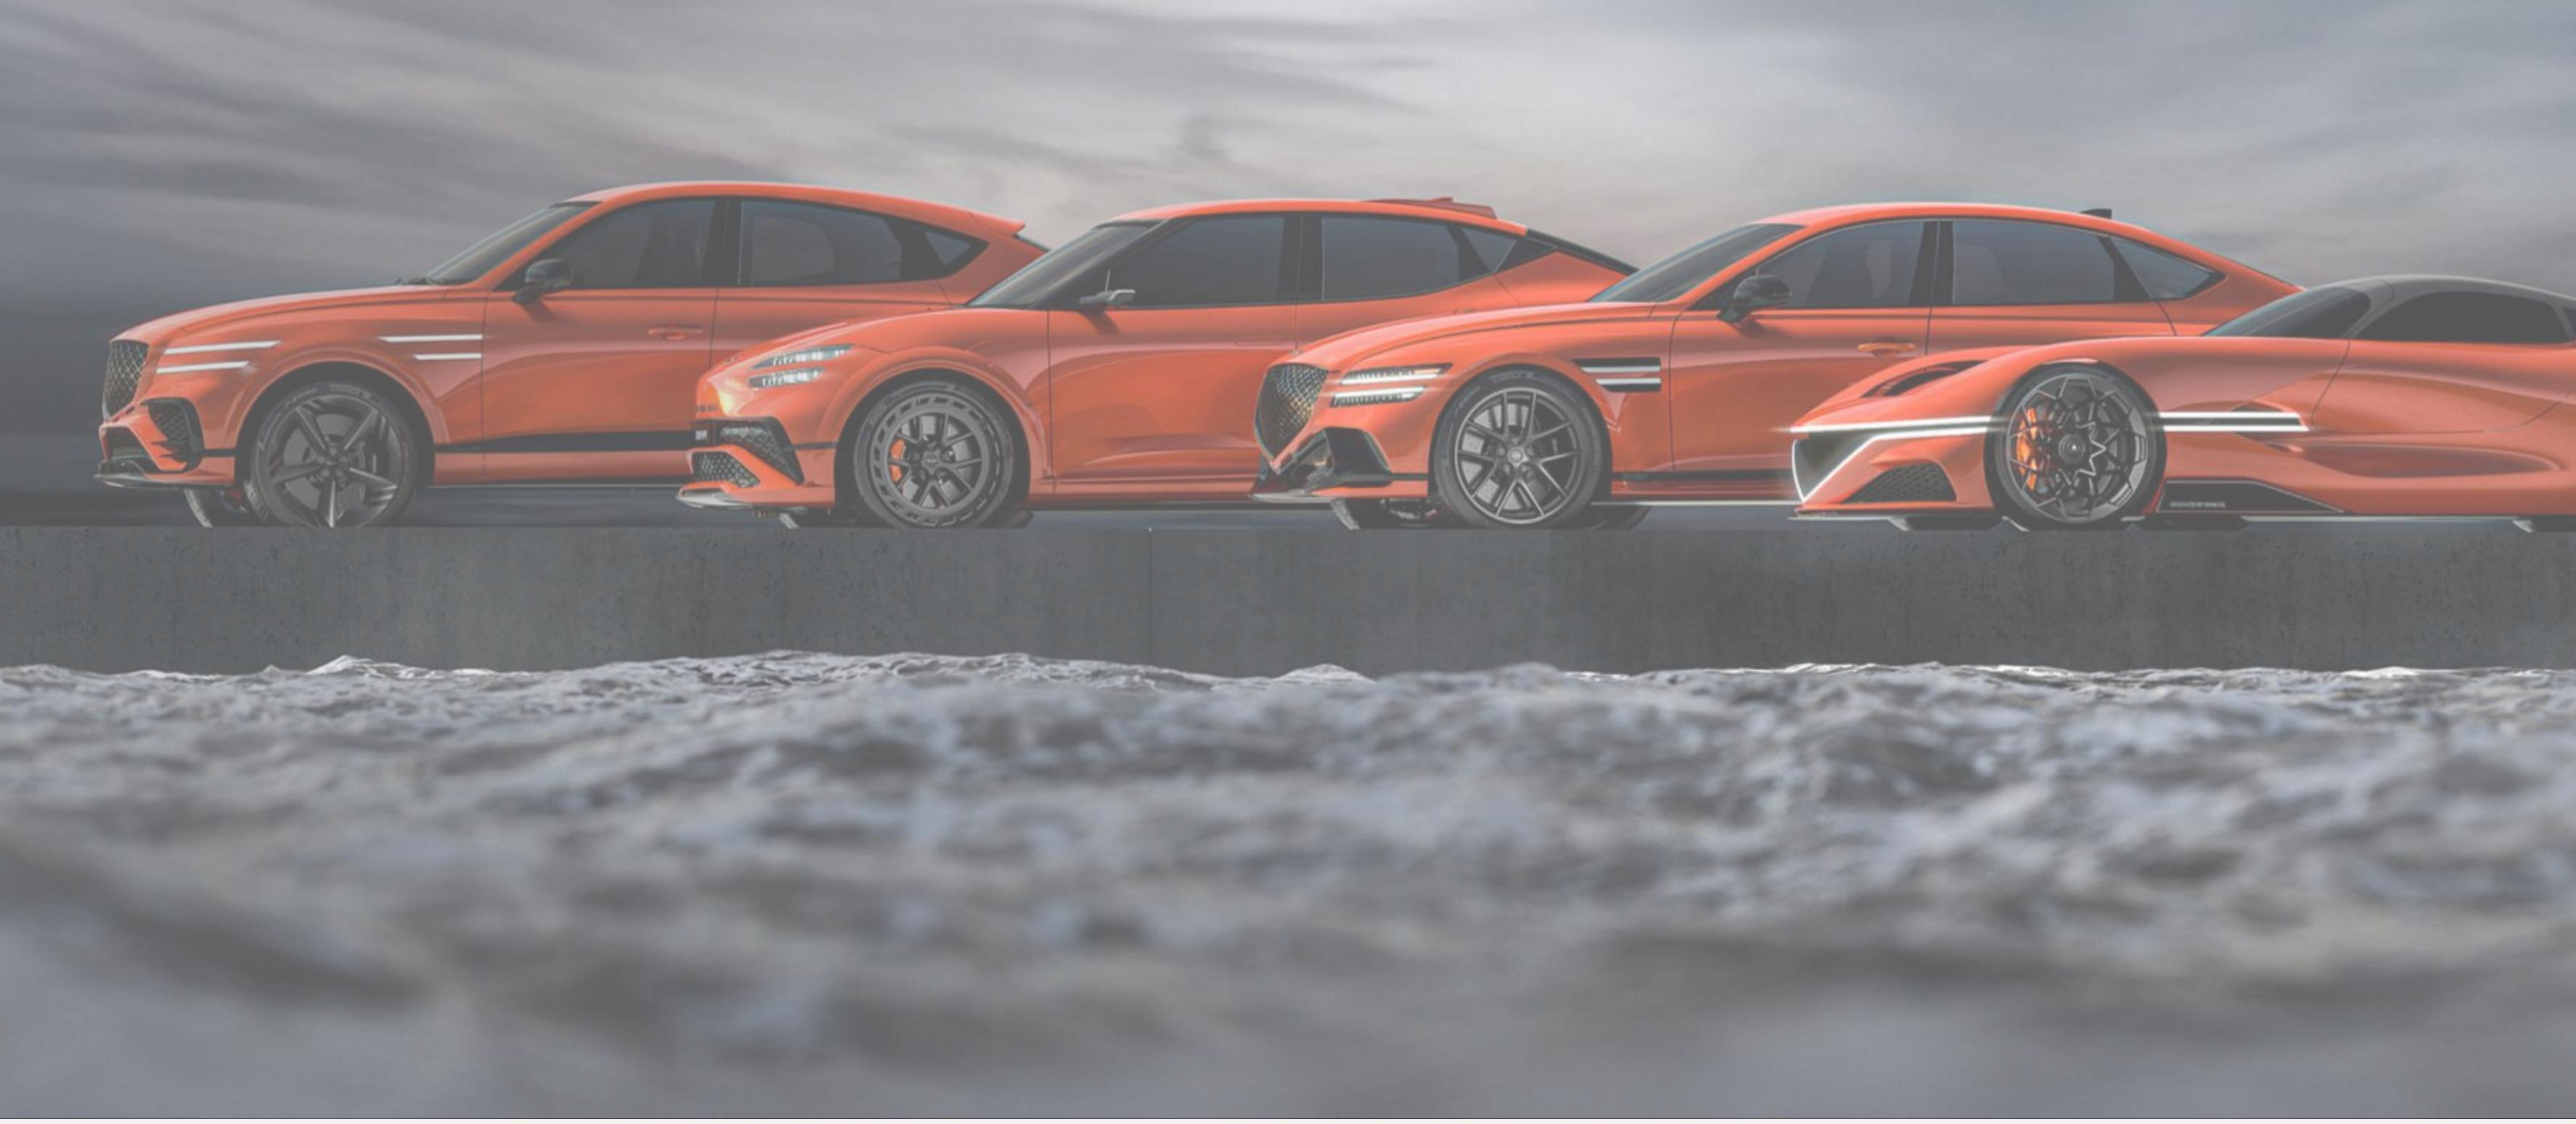

요약: 이 이미지는 자동차 사진입니다.

[1] figure-10-17.jpg


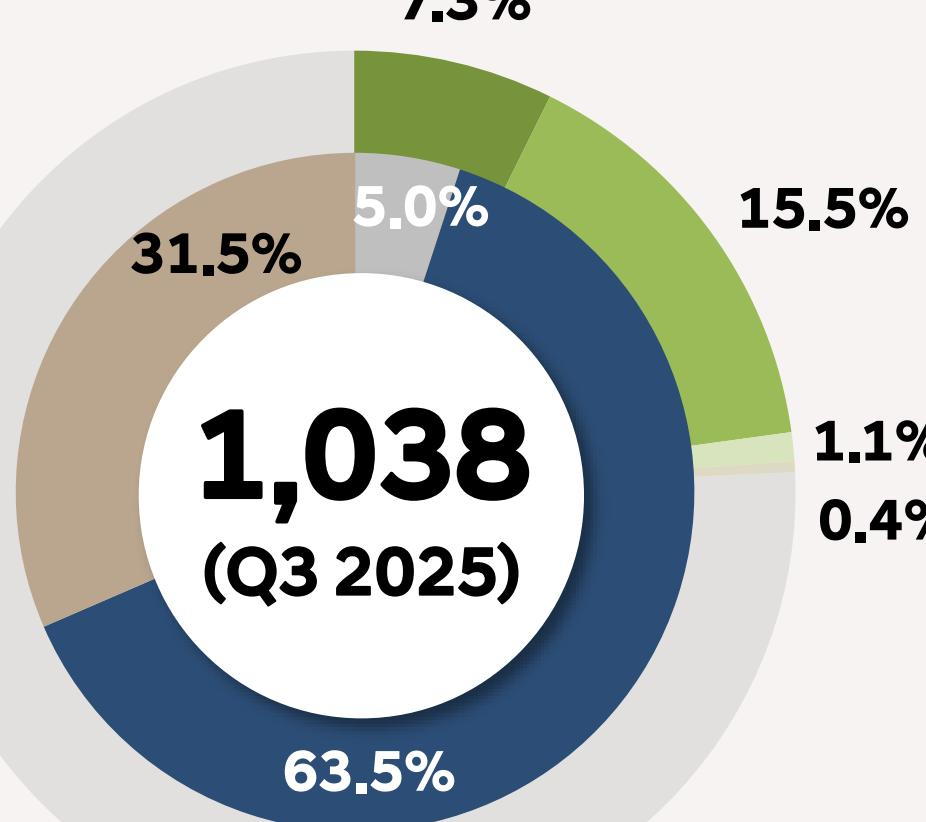

요약: 1. 그래프 종류: 도넛
2. 제목: 1,038 (Q3 2025)
   범례 항목: 없음 (범례 항목이 명시되어 있지 않음)
   축 이름: 없음 (축 이름이 명시되어 있지 않음)
3. 범례 항목별 수치: 
   - 항목: 기간 값 → 기간 값 (범례 항목이 명시되어 있지 않음)
4. 주제 추론: 특정 항목의 비율 분포 (정확한 항목은 불명확함)

[2] figure-14-18.jpg


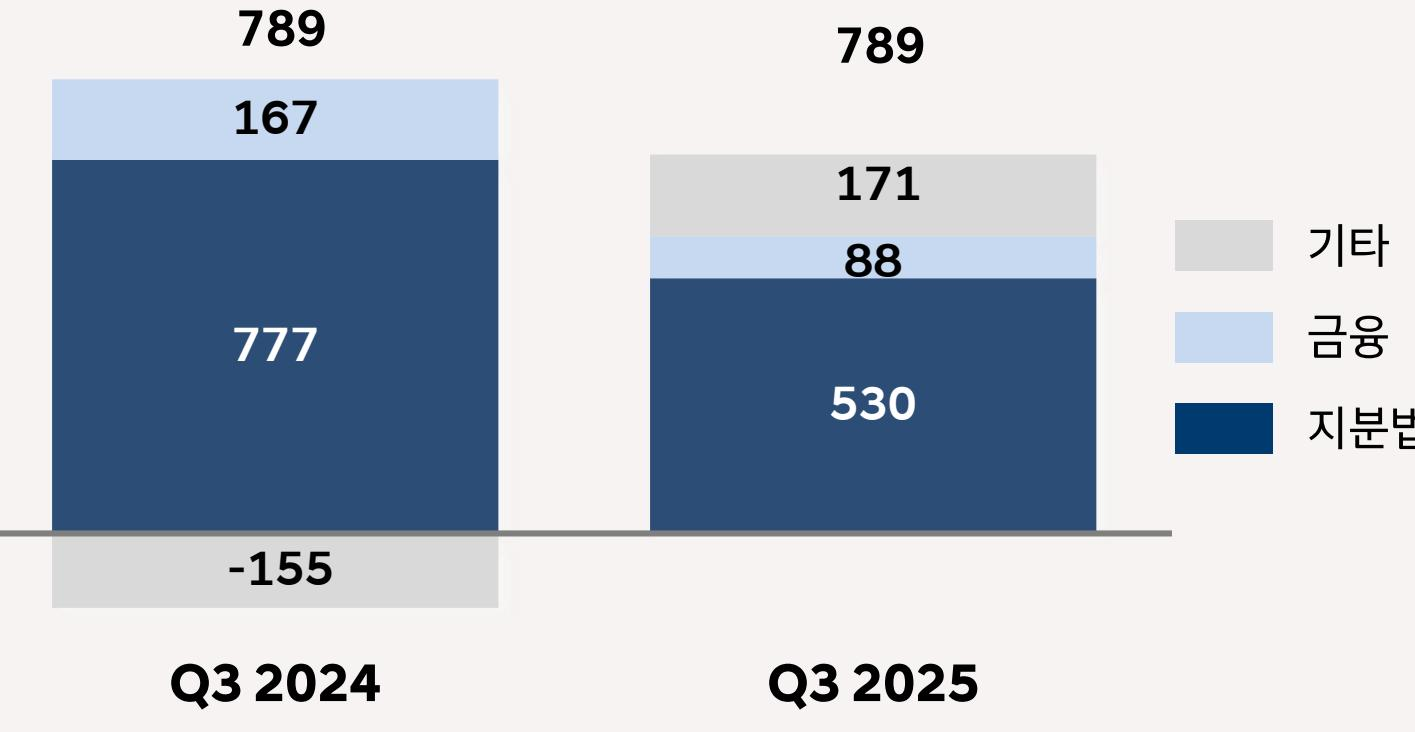

요약: 1. 그래프 종류: 막대 그래프
2. 제목: 없음, 범례 항목: 기타, 금융, 지분법, 축 이름: 없음
3. 범례 항목별 수치:
   - 기타: Q3 2024 167 → Q3 2025 171
   - 금융: Q3 2024 777 → Q3 2025 530
   - 지분법: Q3 2024 -155 → Q3 2025 88
4. 주제: 재무 항목별 변화 분석

[3] figure-14-19.jpg


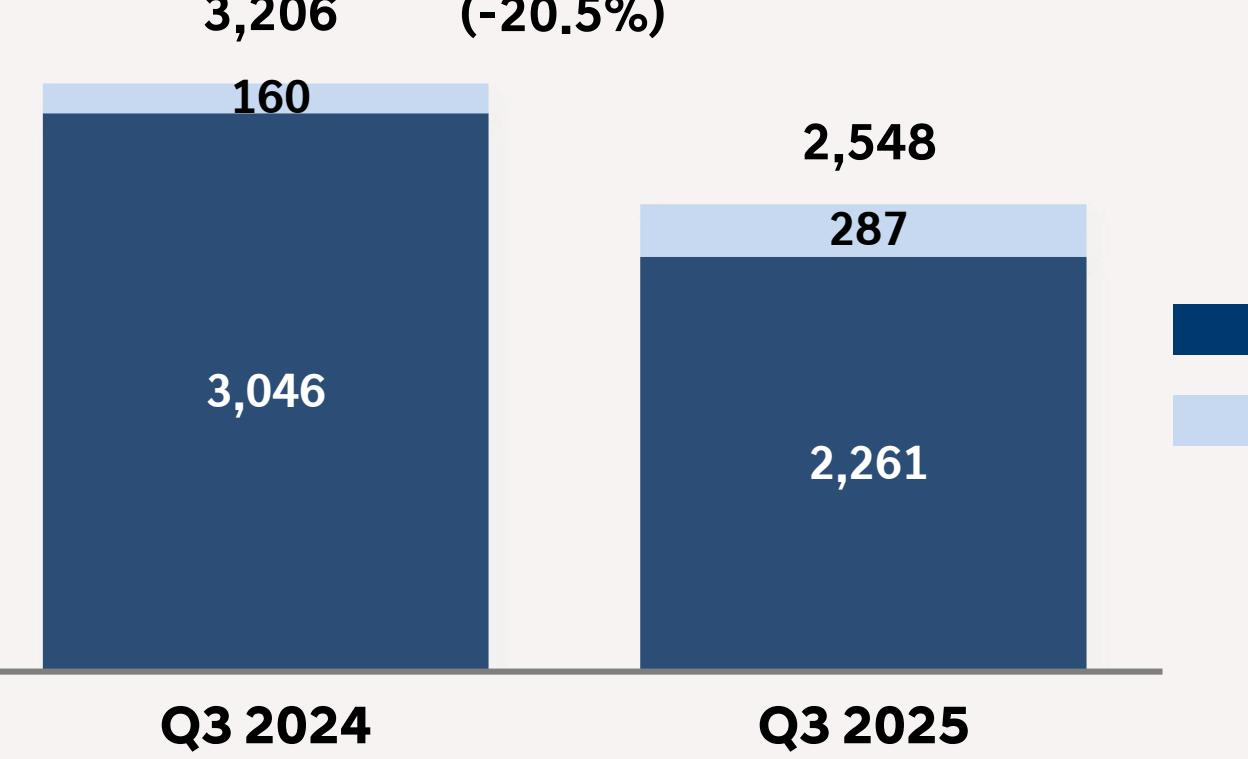

요약: 1. 그래프 종류: 막대 그래프  
2. 제목: 없음 (제목이 보이지 않음)  
   범례 항목: 없음 (범례가 보이지 않음)  
   축 이름: 없음 (축 이름이 보이지 않음)  
3. 수치:  
   - Q3 2024: 3,206 → Q3 2025: 2,548  
   - Q3 2024: 3,046 → Q3 2025: 2,261  
4. 주제 추론: 연도별 판매량 변화

[4] figure-3-2.jpg


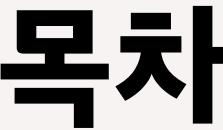

요약: 그래프가 아닌 사진이나 로고입니다.

[5] figure-4-3.jpg


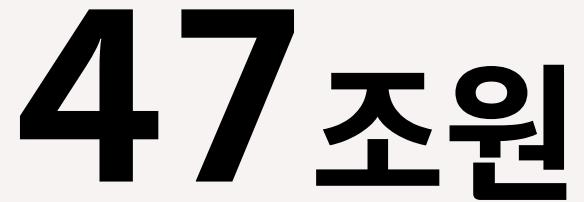

요약: 그래프가 아닌 사진입니다. "47 조원"이라는 텍스트가 포함되어 있습니다.

[6] figure-4-4.jpg


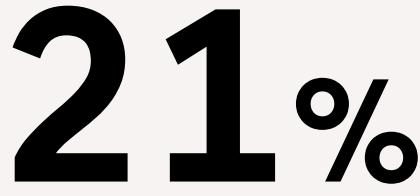

요약: 그래프가 아닌 숫자 이미지입니다.

[7] figure-6-10.jpg


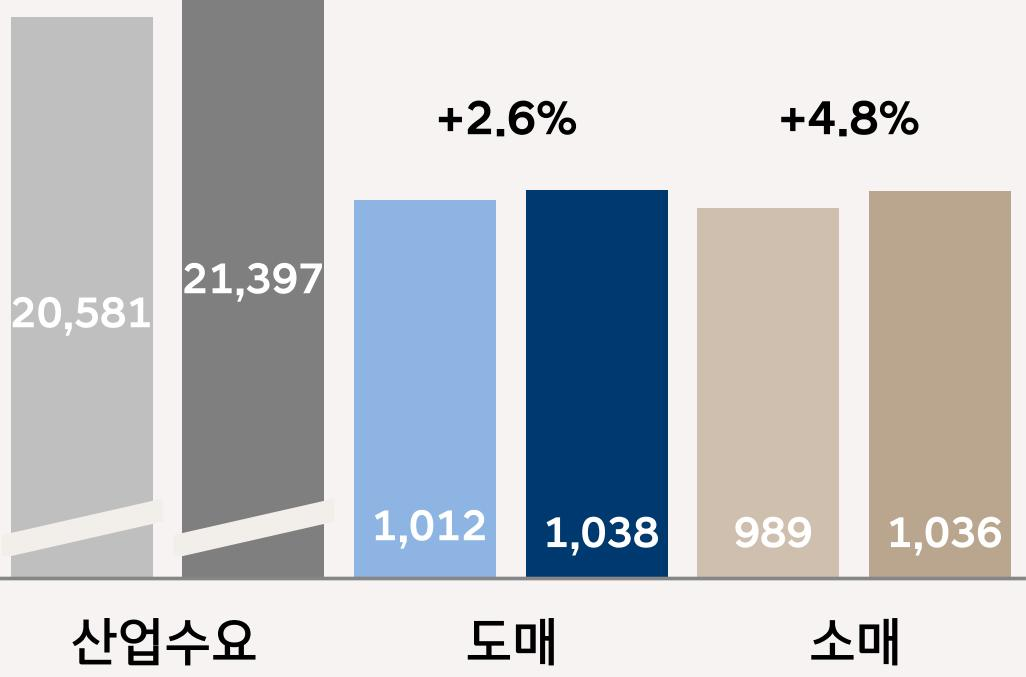

요약: 1. 그래프 종류: 막대 그래프  
2. 제목: 없음, 범례 항목: 산업수요, 도매, 소매, 축 이름: 없음  
3. 산업수요: Q1 2023 20,581 → Q1 2024 21,397  
   도매: Q1 2023 1,012 → Q1 2024 1,038  
   소매: Q1 2023 989 → Q1 2024 1,036  
4. 주제: 산업수요 및 도매, 소매의 연도별 변화 추세

[8] figure-6-5.jpg


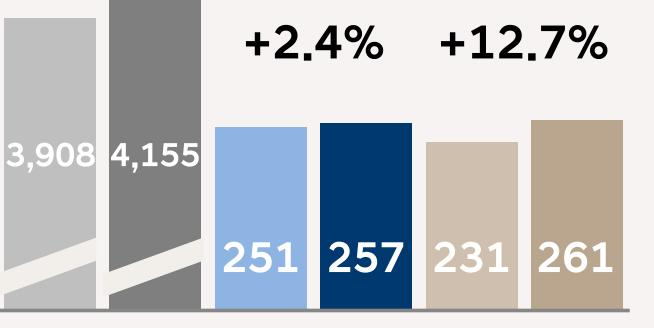

요약: 1. 그래프 종류: 막대 그래프  
2. 제목: 없음, 범례 항목: 없음, 축 이름: 없음  
3. 수치:  
   - 항목1: 기간 값 3,908 → 4,155  
   - 항목2: 기간 값 251 → 257  
   - 항목3: 기간 값 231 → 261  
4. 주제 추론: 기간별 성과 변화 (성장률)

[9] figure-6-6.jpg


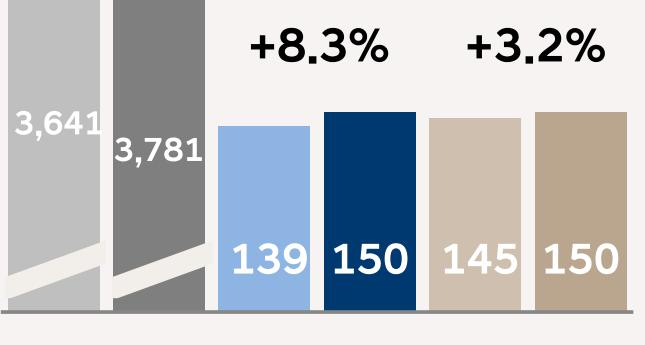

요약: 1. 그래프 종류: 막대 그래프  
2. 제목: 없음, 범례 항목: 없음, 축 이름: 없음  
3. 수치: 139: 이전 기간 3,641 → 현재 3,781, 150: 이전 기간 139 → 현재 150, 145: 이전 기간 150 → 현재 145  
4. 주제 추론: 성장률 변화 또는 성과 비교.

[10] figure-6-7.jpg


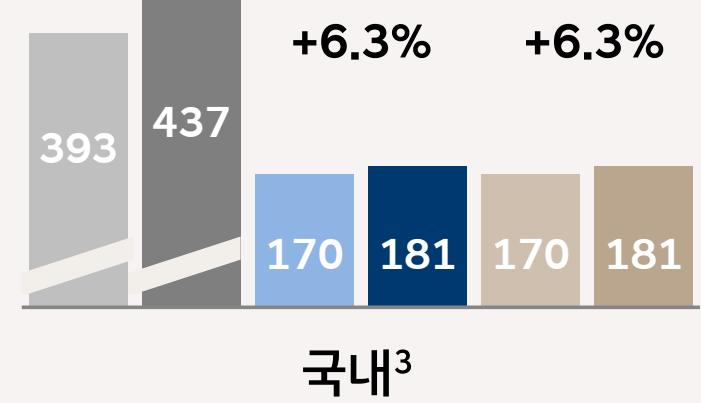

요약: 1. 그래프 종류: 막대 그래프  
2. 제목: 국내  
   범례 항목: 없음 (수치만 표시됨)  
   축 이름: 없음 (수치만 표시됨)  
3. 수치:  
   - 393: 기간 값 → 437  
   - 170: 기간 값 → 181  
   - 170: 기간 값 → 181  
4. 주제 추론: 국내 판매량 변화 추세

[11] figure-6-8.jpg


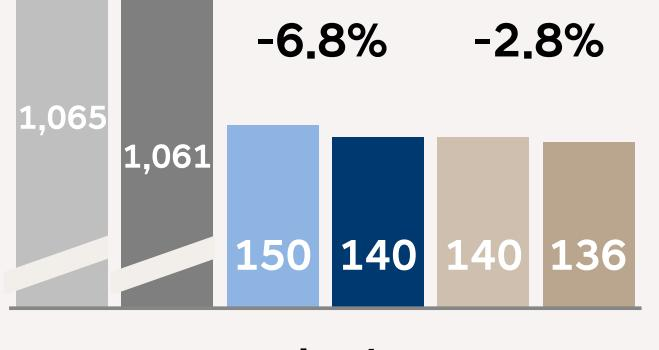

요약: 1. 그래프 종류: 막대 그래프  
2. 제목: 없음, 범례 항목: 없음, 축 이름: 없음  
3. 범례 항목별 수치:  
   - 항목1: 기간 값 1,065 → 기간 값 1,061  
   - 항목2: 기간 값 150 → 기간 값 140  
   - 항목3: 기간 값 140 → 기간 값 140  
   - 항목4: 기간 값 136  
4. 주제 추론: 연도별 수익 변화 및 감소율 분석

[12] figure-6-9.jpg


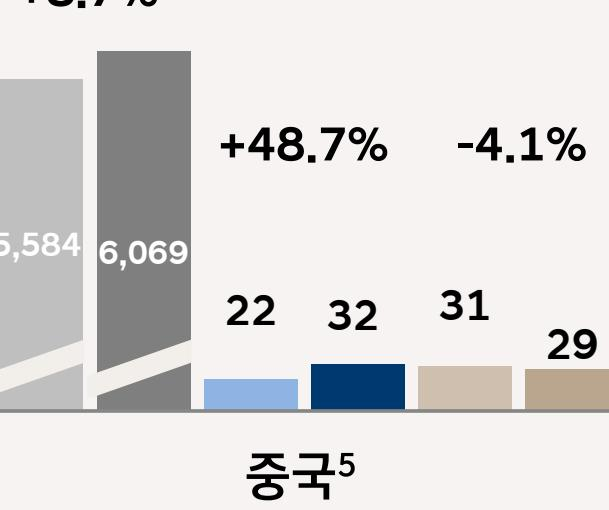

요약: 1. 그래프 종류: 막대 그래프  
2. 제목: 없음, 범례 항목: 없음, 축 이름: 중국  
3. 수치:  
   - 22: Q1 2023 22 → Q1 2024 32  
   - 31: Q1 2023 31 → Q1 2024 29  
4. 주제: 중국 시장의 판매 변화 추세

[13] figure-7-11.jpg


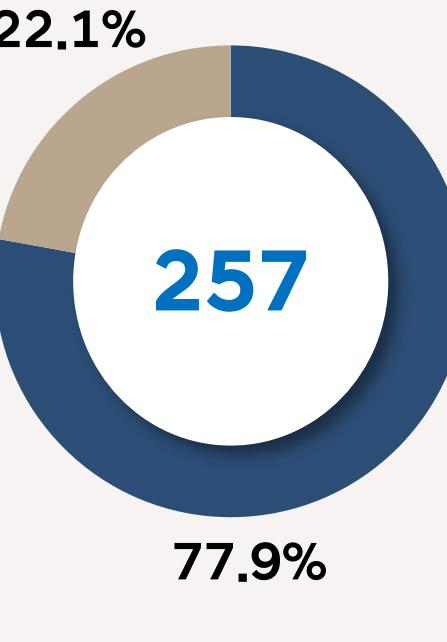

요약: 1. 그래프 종류: 도넛 차트
2. 제목: 없음, 범례 항목: 없음, 축 이름: 없음
3. 범례 항목별 수치: 
   - 항목1: 2023 22.1% → 2024 77.9%
4. 추론한 주제: 전체 수치 대비 비율 분포 (예: 특정 항목의 비율)

[14] figure-7-12.jpg


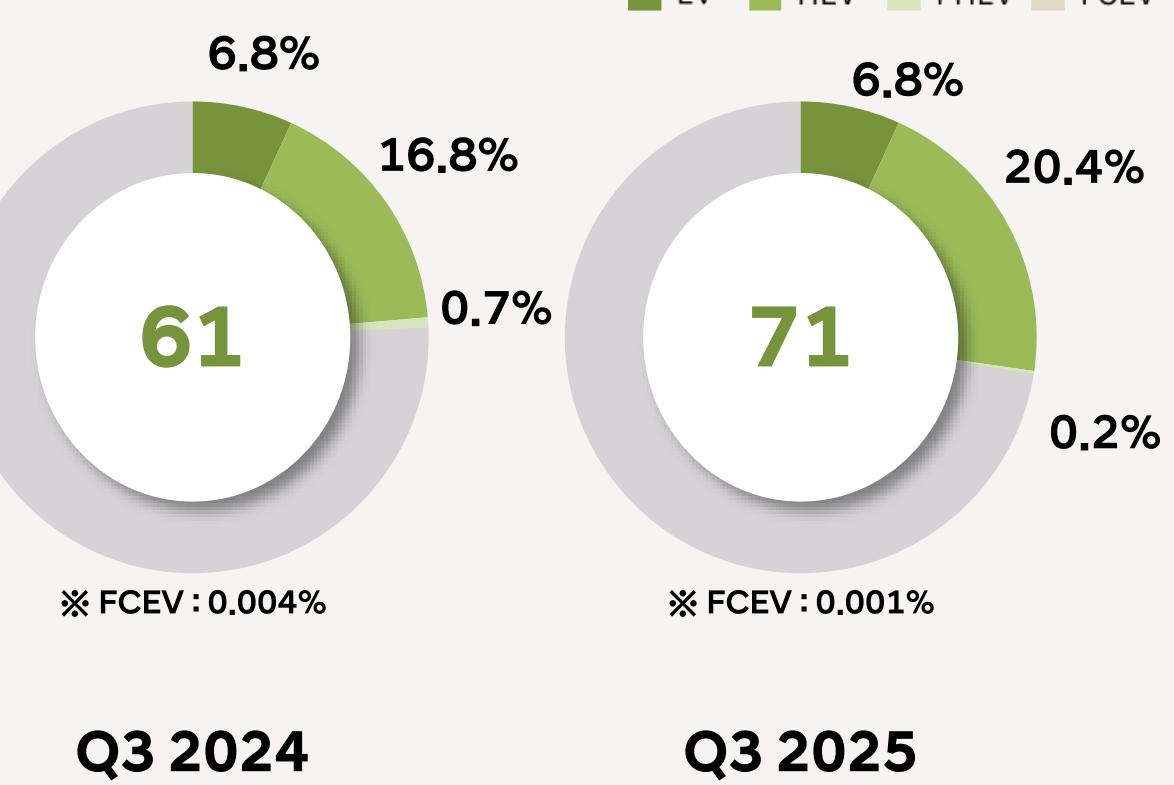

요약: 1. 그래프 종류: 도넛 차트  
2. 제목: 없음  
   범례 항목: EV, HEV, PHEV, FCEV  
   축 이름: 없음  
3. EV: Q3 2024 6.8% → Q3 2025 6.8%  
   HEV: Q3 2024 16.8% → Q3 2025 20.4%  
   PHEV: Q3 2024 0.7% → Q3 2025 0.2%  
   FCEV: Q3 2024 0.004% → Q3 2025 0.001%  
4. 주제: 전기차 및 하이브리드차 판매 비중 변화

[15] figure-8-13.jpg


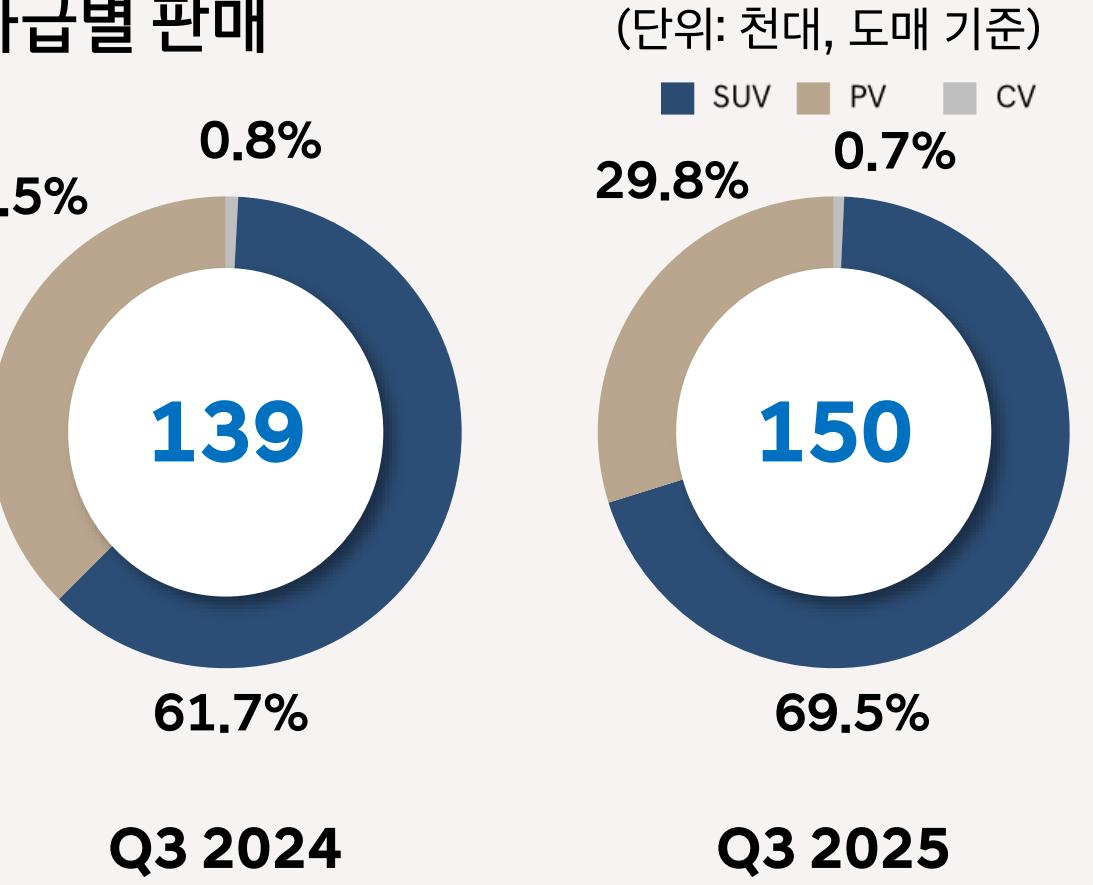

요약: 1. 그래프 종류: 도넛
2. 제목: 차급별 판매
   범례 항목: SUV, PV, CV
   축 이름: (단위: 천대, 도매 기준)
3. 범례 항목별 수치: 
   - SUV: Q3 2024 61.7% → Q3 2025 69.5%
   - PV: Q3 2024 0.8% → Q3 2025 0.7%
   - CV: Q3 2024 0.5% → Q3 2025 0.0%
4. 주제: 차급별 판매 비중 변화

[16] figure-8-14.jpg


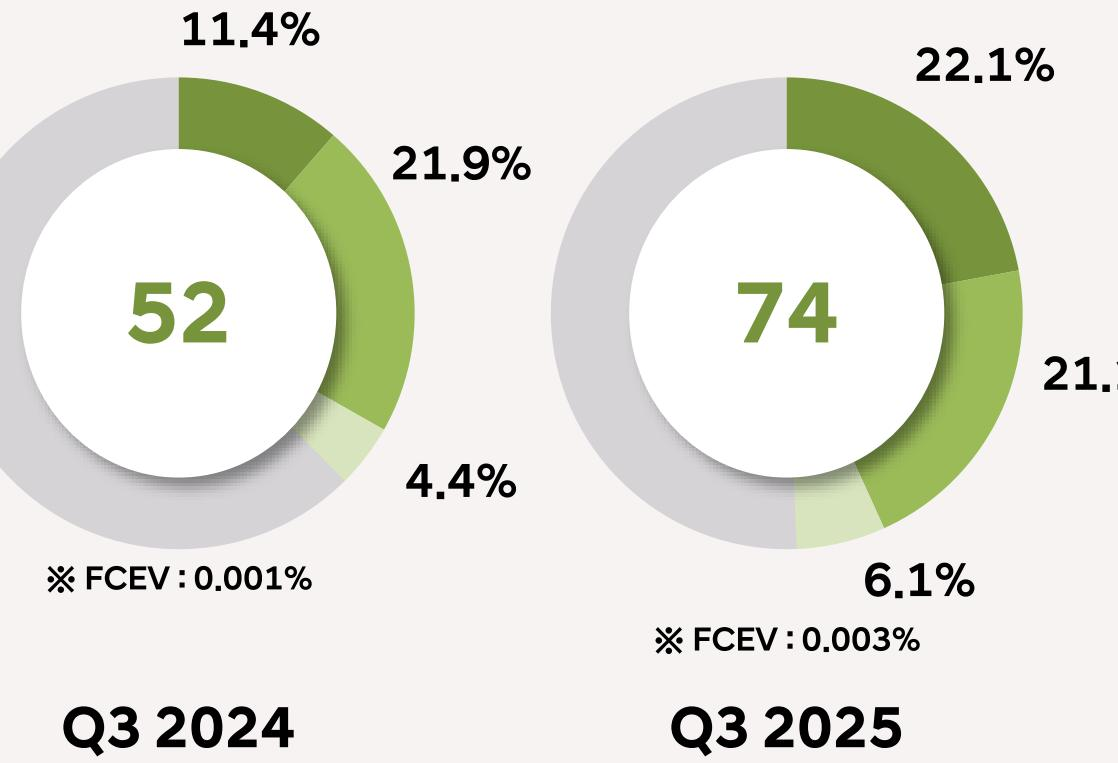

요약: 1. 그래프 종류: 도넛 차트  
2. 제목: 없음  
   범례 항목: 없음  
   축 이름: 없음  
3. 수치:  
   - 52: Q3 2024 11.4% → Q3 2025 22.1%  
   - 52: Q3 2024 21.9% → Q3 2025 21.9%  
   - 52: Q3 2024 4.4% → Q3 2025 6.1%  
4. 주제: 친환경차 판매 비중 변화

[17] figure-9-15.jpg


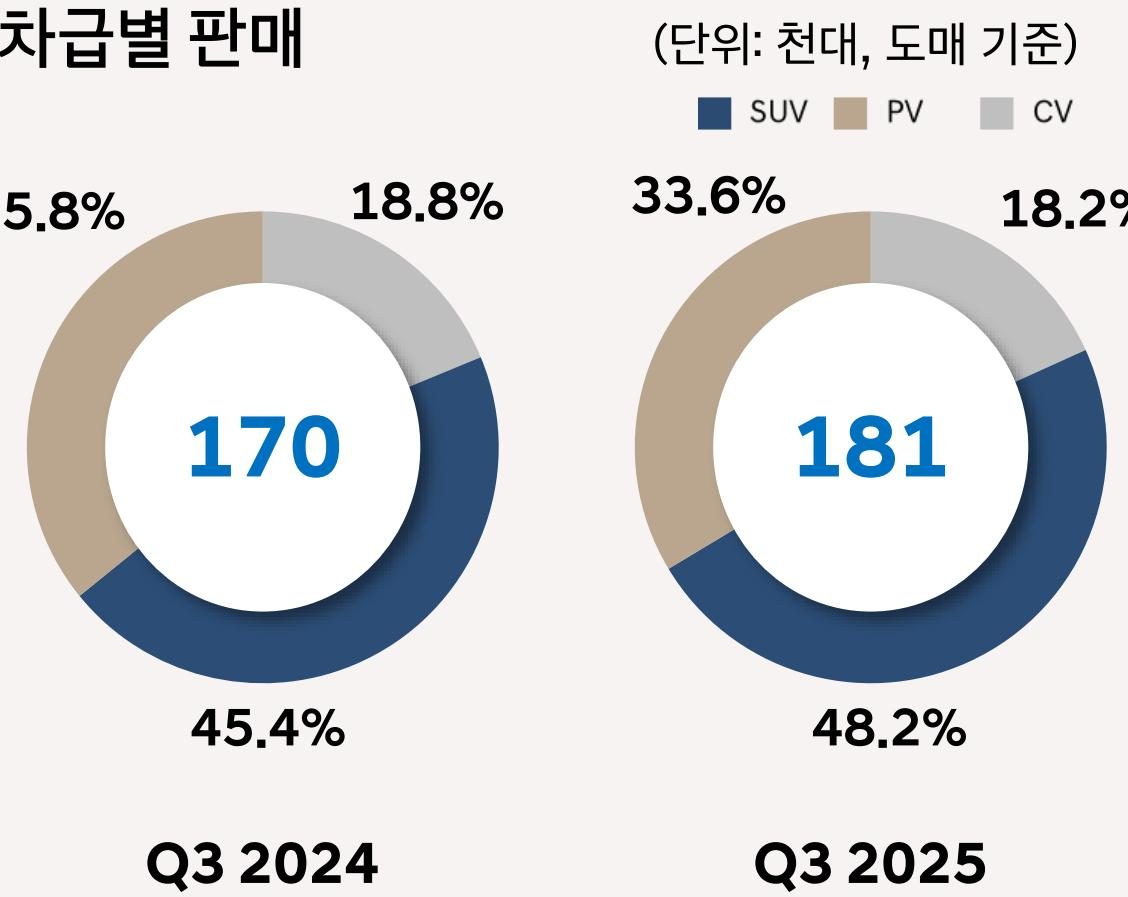

요약: 1. 그래프 종류: 도넛
2. 제목: 차급별 판매
   범례 항목: SUV, PV, CV
   축 이름: 없음
3. SUV: Q3 2024 45.4% → Q3 2025 48.2%  
   PV: Q3 2024 5.8% → Q3 2025 18.2%  
   CV: Q3 2024 18.8% → Q3 2025 33.6%
4. 주제: 차급별 판매 비중 변화

[18] figure-9-16.jpg


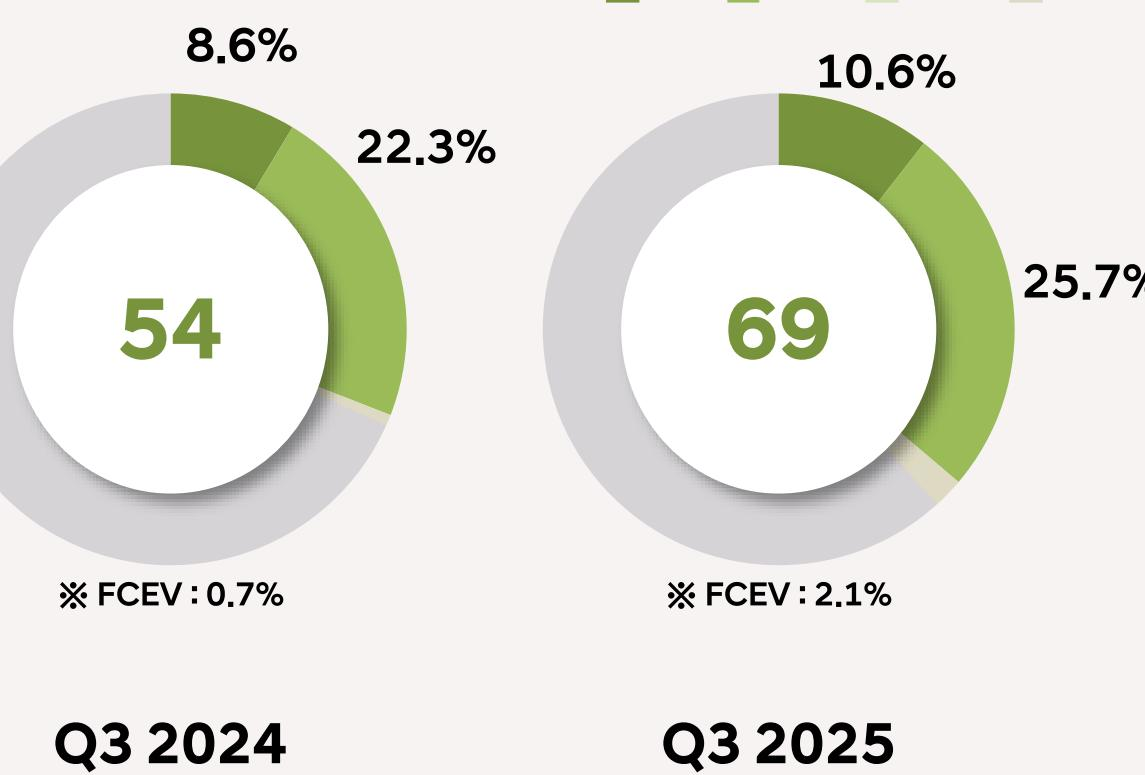

요약: 1. 그래프 종류: 도넛 차트
2. 제목: 없음, 범례 항목: 없음, 축 이름: 없음
3. 수치: 
   - Q3 2024: 54 
   - Q3 2025: 69 
   - FCEV: Q3 2024 0.7% → Q3 2025 2.1%
4. 주제: 친환경차 판매 비중 변화



In [17]:
from IPython.display import Image, display

for i, (img_file, summary) in enumerate(zip(image_files, image_summaries)):
    print("="*60)
    print(f"[{i}] {img_file.name}")
    print("="*60)
    display(Image(filename=str(img_file), width=450))
    print("요약:", summary)
    print()

## 다중 벡터 검색기 + 최종 체인
---

In [18]:
import os
import re
import time
import uuid
from pathlib import Path
from dotenv import load_dotenv

try:
    from langchain_classic.retrievers.multi_vector import MultiVectorRetriever
except ImportError:
    print("MultiVectorRetriever 클래스가 필요합니다")

try:
    from langchain_core.stores import InMemoryStore
except ImportError:
    print("InMemoryStore 클래스가 필요합니다")

from langchain_chroma import Chroma
from langchain_openai import OpenAIEmbeddings

vectorstore = Chroma(
    collection_name = "multimodal_rag", embedding_function=OpenAIEmbeddings(model="text-embedding-3-small")
)
store = InMemoryStore()
id_key = "doc_id"
retriever = MultiVectorRetriever(
    vectorstore=vectorstore, docstore=store, id_key=id_key,
    search_kwargs={"k": 6}
)

print("검색기 생성 완료")


검색기 생성 완료


In [19]:
from langchain_core.documents import Document


def add_documents(retriever, doc_summaries, doc_contents):
    """요약본은 벡터 DB에, 원본은 docstore에 '같은 id'로 저장합니다."""
    doc_ids = []

    doc_ids = [str(uuid.uuid4()) for _ in doc_contents]

    summary_docs = [
        Document(page_content= s, metadata={id_key:doc_ids[i]})
        for i, s in enumerate(doc_summaries)
    ]

    retriever.vectorstore.add_documents(summary_docs)

    retriever.docstore.mset(list(zip(doc_ids, doc_contents)))


if text_summaries:
    add_documents(retriever, text_summaries, texts_2k_token)
if table_summaries:
    add_documents(retriever, table_summaries, tables)
if image_summaries:
    add_documents(retriever, image_summaries, img_base64_list)

print("색인 완료")
print(" 벡터 DB에 저장된 요약 수:", len(vectorstore.get()["ids"]))

색인 완료
 벡터 DB에 저장된 요약 수: 40


In [20]:
questions = [
    "3분기 미국 시장 점유율과 고수익 차종 판매 비중은?",
    "3분기 매출액과 영업이익은 전분기(Q2 2025) 대비 얼마나 변했나?",
    "국내 시장의 SUV 판매 비중은 전년 대비 어떻게 변했나?",
    "3분기 글로벌 산업수요·도매·소매 판매는 전년 대비 각각 몇 % 변했나?",
    "	미국 시장의 HEV 판매 비중은 전년 대비 어떻게 변했나?",
]

results = []
for qi, q in enumerate(questions, 1):
    found = retriever.invoke(q)


    print(f"[Q{qi}] {q}")
    print("검색된 원본 수:", len(found))
    print()


    for i, doc in enumerate(found):
        content = doc.page_content if hasattr(doc, "page_content") else doc
        is_image = bool(re.match("^[A-Za-z0-9+/]{100,}={0,2}$", content))
        kind = "이미지(Base64)" if is_image else "텍스트/표"
        print(f"[{i}] {kind} - 길이 {len(content):,}자")
        print("    ", content[:120].replace("\n"," "), "...")
    print("-" * 60)

[Q1] 3분기 미국 시장 점유율과 고수익 차종 판매 비중은?
검색된 원본 수: 6

[0] 텍스트/표 - 길이 193자
     사 / 조원  역대 최대 3 분 기 매출액 기록  EI TH 「 보 본 격 화 와 이로 인한 수요 둔화 우려 불구, 세로 역대 3 분 기 기준 최대 매출액 기록  6.3%  미국 시장 지배력 강화  다 변 화 된 『 ...
[1] 텍스트/표 - 길이 369자
     21%  고수익 차종 판 매 비중 확대 지속  『16 ㄷ \- 제 네 시 스 합산 판매 비중 21% 기 록 으로 2 개 분기 연속 비중 20% 이상 달성  데이트 ol A KO |! 시  P.5  P.6~8  P.9 ...
[2] 텍스트/표 - 길이 412자
     03 2024 소매  ㅣ  Q3 2025 소매  (단위 : 천대)  -0.4%  -6.8% -2.8%  +8.7%  +48.7% -4.1% 6,069 22 31 32 29 we eee ES ee 325  iO) er ...
[3] 텍스트/표 - 길이 328자
     럽  +6.3% +6.3% 7704181 국내:  +1.0% +3.2% | 65 | 00 | 05 on 5  82  -18.6% -12.3%  아태  -2.1% +4.3% +13.6% +12.9% so | 76 |  ...
[4] 텍스트/표 - 길이 346자
     i SUV § Pv  cv  72.7%  22.1% 257 77.9%  Q3 2024  Q3 2025  MEV MPHEV  PHEV  6.8% 20.4% 71 0.2% %% FCEV : 0.004% FCEV : 0. ...
[5] 텍스트/표 - 길이 249자
     * 도매 판매 기준 / 지역별 전체 판 매 대 수 대비 비중  FCEV Market Summary  v 전년 동기 대비 영업 일수 oak 수 S724 추석 연휴 9 월 ), 신 차 효과 영 3 분 기 도매 판매량 Y ...
----------------------------------------------------

In [21]:
def split_image_text_types(docs):
    b64_images = []
    texts_out = []

    for doc in docs:
        doc = str(doc.page_content if isinstance(doc, Document) else doc)
        if re.match("^[A-Za-z0-9+/]{100,}={0,2}$", doc):
            b64_images.append(doc)
        else:
            texts_out.append(doc)
    return {"images": b64_images, "texts": texts_out}

split_data = split_image_text_types(found)
print("이미지", len(split_data["images"]), "건")
print("표", len(split_data["texts"]), "건")

이미지 0 건
표 6 건


In [22]:
from langchain_core.messages import HumanMessage
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatMessagePromptTemplate
from langchain_core.runnables import RunnableLambda, RunnablePassthrough
from langchain_openai import ChatOpenAI


def img_prompt_func(data_dict):
    messages = []

    for image in data_dict["context"]["images"]:
        messages.append({
            "type": "image_url",
            "image_url": {"url": f"data:image/jpeg;base64,{image}"}
        })
    formatted_texts = "\n".join(data_dict["context"]["texts"])
    messages.append({
        "type": "text",
        "text": ("자료를 근거로 질문에 한국어로 답하세요\n"
                 "자료에 없는 내용은 모른다고 답하세요\n\n"
                 f"질문: {data_dict['question']}\n\n"
                 f"참고 텍스트 : \n {formatted_texts}"
                 ),
    })
    return [HumanMessage(content=messages)]


model = ChatOpenAI(temperature=0, model="gpt-4o-mini", max_tokens=1024)

chain = (
    {
        "context" : retriever | RunnableLambda(split_image_text_types),
        "question": RunnablePassthrough(),
    } | RunnableLambda(img_prompt_func)
    | model
    | StrOutputParser()
)

print("최종 체인 조립 완료")

최종 체인 조립 완료


In [23]:
for qi, q in enumerate(questions, 1):
    start = time.time()

    answer = chain.invoke(q)

    print(f"[Q{qi}] {q}")
    print(f"답변 생성 : {time.time() - start:.1f}초")
    print("="*60)
    print(answer)
    print()

[Q1] 3분기 미국 시장 점유율과 고수익 차종 판매 비중은?
답변 생성 : 3.3초
3분기 미국 시장 점유율은 6.3%이며, 고수익 차종 판매 비중은 21%입니다.

[Q2] 3분기 매출액과 영업이익은 전분기(Q2 2025) 대비 얼마나 변했나?
답변 생성 : 2.4초
3분기(Q3 2025) 매출액은 46,721억원으로 전분기(Q2 2025) 대비 3.2% 감소하였고, 영업이익은 2,037억원으로 전분기 대비 29.6% 감소하였습니다.

[Q3] 국내 시장의 SUV 판매 비중은 전년 대비 어떻게 변했나?
답변 생성 : 1.5초
국내 시장의 SUV 판매 비중은 Q3 2024에서 45.4%였고, Q3 2025에서는 48.2%로 증가했습니다. 따라서 전년 대비 SUV 판매 비중이 증가했습니다.

[Q4] 3분기 글로벌 산업수요·도매·소매 판매는 전년 대비 각각 몇 % 변했나?
답변 생성 : 1.7초
자료에 따르면, 3분기 글로벌 산업수요는 전년 대비 +2.6% 변했으며, 도매는 +4.8%, 소매는 +2.4% 변했습니다.

[Q5] 	미국 시장의 HEV 판매 비중은 전년 대비 어떻게 변했나?
답변 생성 : 1.0초
미국 시장의 HEV 판매 비중은 전년 대비 20.4%로 기록되었습니다.



In [24]:
# 비교용 텍스트 전용 RAG
from langchain_core.prompts import ChatPromptTemplate

text_vectorstore = Chroma(
    collection_name="text_only_rag",
    embedding_function=OpenAIEmbeddings(model="text-embedding-3-small"),
)
text_vectorstore.add_texts(texts_2k_token)
text_retriever = text_vectorstore.as_retriever(search_kwargs={"k": 6})

text_prompt = ChatPromptTemplate.from_template(
    "자료를 근거로 질문에 한국어로 답하세요\n"
    "자료에 없는 내용은 모른다고 답하세요\n\n"
    "질문: {question}\n\n"
    "참고 텍스트 : \n {context}"
)

def format_docs(docs):
    return "\n".join(d.page_content for d in docs)

text_only_chain = (
    {"context": text_retriever | RunnableLambda(format_docs),
     "question": RunnablePassthrough()}
     | text_prompt
     | model
     | StrOutputParser()
)

print("비교용 텍스트 전용 RAG 준비 완료")

비교용 텍스트 전용 RAG 준비 완료


In [27]:
# ── 8-2. Before / After 출력 ───────────────────────────────
for qi, q in enumerate(questions, 1):
# 1) 구분선과 질문 출력
    print("=" * 60)
    print(f"[Q{qi}] 질문:", q)
    print("=" * 60)

    # 2) [BEFORE] 텍스트 전용 RAG
    before = text_only_chain.invoke(q)
    print("\n[BEFORE] 텍스트 전용 RAG")
    print("-" * 60)
    print(before)

    # 3) [AFTER] 멀티모달 RAG
    after = chain.invoke(q)
    print("\n[AFTER] 멀티모달 RAG")
    print("-" * 60)
    print(after)
    print()

# 4) 안내
print("\n" + "=" * 60)
print("이 출력 전체를 캡처해 README.md에 넣으세요.")

[Q1] 질문: 3분기 미국 시장 점유율과 고수익 차종 판매 비중은?

[BEFORE] 텍스트 전용 RAG
------------------------------------------------------------
3분기 미국 시장 점유율은 6.3%이며, 고수익 차종 판매 비중은 21%입니다.

[AFTER] 멀티모달 RAG
------------------------------------------------------------
3분기 미국 시장 점유율은 6.3%이며, 고수익 차종 판매 비중은 21%입니다.

[Q2] 질문: 3분기 매출액과 영업이익은 전분기(Q2 2025) 대비 얼마나 변했나?

[BEFORE] 텍스트 전용 RAG
------------------------------------------------------------
Q3 2025의 매출액은 42,928억원으로, Q2 2025 대비 3,793억원(8.8%) 증가했습니다. 영업이익은 Q3 2025에서 -1,044억원으로, Q2 2025 대비 29.2% 감소했습니다.

[AFTER] 멀티모달 RAG
------------------------------------------------------------
3분기(Q3 2025) 매출액은 46,721억원으로 전분기(Q2 2025) 대비 3.2% 감소하였고, 영업이익은 2,037억원으로 전분기 대비 29.6% 감소하였습니다.

[Q3] 질문: 국내 시장의 SUV 판매 비중은 전년 대비 어떻게 변했나?

[BEFORE] 텍스트 전용 RAG
------------------------------------------------------------
국내 시장의 SUV 판매 비중은 전년 대비 48.2%로 증가했습니다.

[AFTER] 멀티모달 RAG
------------------------------------------------------------
국내 시장의 SUV 판매 비중은 Q3 2024에서 45.4%였고, Q3 2025에서는 4